<a href="https://colab.research.google.com/github/mercygerman/MODULE_2_CASE_EXERCISE-_1/blob/MODULE_2_CASE_EXERCISE_3/MODULE_2_CASE_EXERCISE3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 QUESTION 1
  
  Complete a full FMECA worksheet for a subsea Christmas tree (minimum 10 failure modes).


SUBSEA CHRISTMAS TREE — FMECA AND PREDICTIVE FEATURE MAPPING
Number of failure modes: 14


,ID,Component,Failure Mode,Failure Effect,Potential Cause,Driving Physics Parameters,Detection / Existing Controls,ML Feature Engineering,Prediction Target,Severity,Occurrence,Detectability,Recommended Action,RPN,Risk Band
0,CT-01,Production master valve,Internal corrosion / wall thinning,Loss of pressure containment; pote...,"CO₂-containing produced fluids, wa...",CO₂ partial pressure; temperature;...,Corrosion probes/coupons where ava...,Corrosion-rate estimate; cumulativ...,Corrosion-rate trend or time until...,9,4,5,Trend wall thickness and chemistry...,180,Medium
1,CT-02,Valve body / connector region,Fatigue cracking,"Crack growth, leakage, loss of con...",Repeated pressure/temperature cycl...,Stress range; cycle count; pressur...,Inspection/NDT where accessible; v...,Cycle counts by stress range; cumu...,Accumulated fatigue damage or esti...,9,4,6,Track load cycles and vibration; r...,216,High
2,CT-03,Choke / production bore,Hydrate blockage,Restricted or blocked flow; pressu...,Low temperature and high pressure ...,Pressure; temperature; water cut/f...,Pressure and temperature trends; f...,Hydrate subcooling; time since shu...,Hydrate risk state or time-to-hydr...,7,5,4,Monitor hydrate margin and inhibit...,140,Medium
3,CT-04,Choke / production passage,Wax deposition,"Reduced bore area, increased press...",Fluid temperature below wax appear...,Temperature profile; wax appearanc...,Differential-pressure trend; flow-...,Temperature below WAT; pressure-dr...,Wax-growth trend or rising restric...,6,5,4,Monitor normalized pressure drop a...,120,Medium
4,CT-05,Choke trim / flow restriction,Erosion,"Material loss, degraded choke cont...",Sand production and high-velocity ...,Sand rate; fluid velocity; particl...,Sand monitoring; choke performance...,Velocity-squared or velocity-power...,Erosion-rate trend or erosion hots...,8,5,5,Monitor sand and operating envelop...,200,High
5,CT-06,Valve stem / actuator seals,Seal degradation or failure,External or internal leakage; loss...,"Ageing, incompatible material, pre...",Pressure cycling; temperature cycl...,Leak testing; actuator/valve funct...,Actuation count; age; pressure-cyc...,Seal-failure probability or time-t...,8,4,5,Trend function-test results and le...,160,Medium
6,CT-07,Hydraulic actuator / control circuit,Actuator fails to operate,Valve cannot open or close on dema...,"Hydraulic supply loss, contaminati...",Hydraulic pressure; fluid cleanlin...,SCM alarms; hydraulic pressure mon...,Response-time trend; command-feedb...,Actuation failure or abnormal resp...,8,4,4,Trend command/feedback and hydraul...,128,Medium
7,CT-08,Valve seat / closure element,Valve fails to seal,Internal leakage across a closed v...,"Seat damage, debris, erosion, wear...",Differential pressure; leakage rat...,Periodic leak/pressure-hold tests;...,Pressure-decay rate; leakage-test ...,Loss-of-sealing risk,9,3,6,Investigate failed or worsening pr...,162,Medium
8,CT-09,Tree connector / hub seal,Connector seal leakage,Loss of containment at a pressure ...,"Seal damage, improper make-up, deb...",Connector preload; pressure and te...,Pressure/leak testing; installatio...,Cycle count; leak-test residuals; ...,Seal leakage anomaly or degradatio...,9,3,6,Verify installation and seal proce...,162,Medium
9,CT-10,Tree control system / sensors,Pressure or temperature sensor drift,"Incorrect operating data, missed a...","Sensor ageing, calibration drift, ...",Calibration offset; sensor age; re...,Calibration; redundant measurement...,Sensor residual against redundant ...,Sensor anomaly or calibration-drif...,7,5,5,Use redundancy and plausibility ch...,175,Medium



MODEL 1 — INTERNAL CORROSION
Python wall loss: 1.00 mm | Hand calculation: 1.00 mm
Python remaining wall: 11.00 mm | Hand calculation: 11.00 mm
Validation: PASSED

MODEL 2 — FATIGUE DAMAGE (MINER'S RULE)
Python damage: 0.20 (20%) | Hand calculation: 0.20 (20%)
Arithmetic remainder to nominal D=1 criterion: 0.80
Validation: PASSED

FMECA CHECKS
14 failure modes present; ratings are within 1–10; all RPN values match S × O × D.
Validation: PASSED


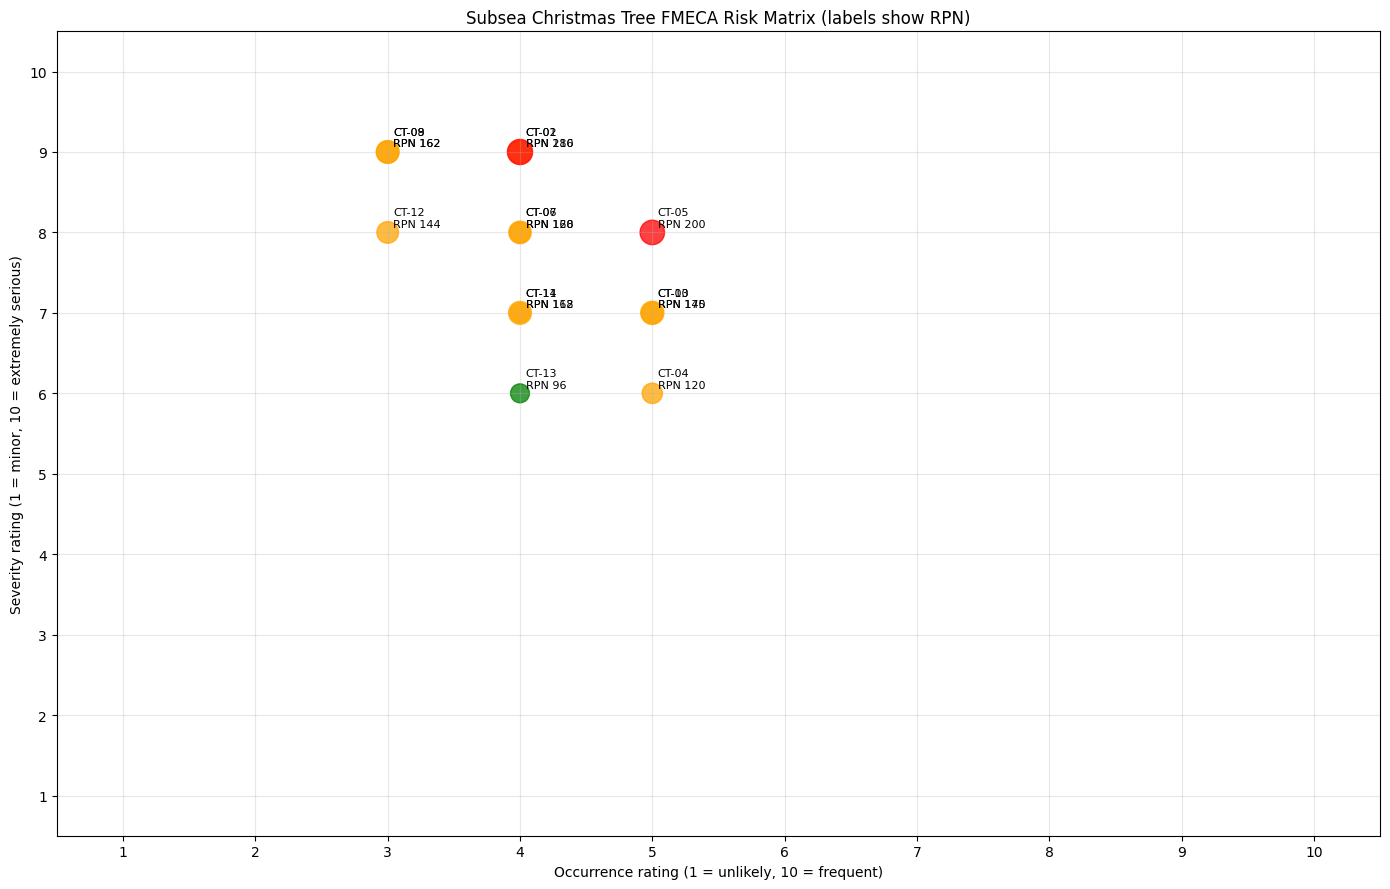


TOP 10 FAILURE MODES BY RPN (FOR REVIEW)


,ID,Failure Mode,Severity,Occurrence,Detectability,RPN,Risk Band
1,CT-02,Fatigue cracking,9,4,6,216,High
4,CT-05,Erosion,8,5,5,200,High
0,CT-01,Internal corrosion / wall thinning,9,4,5,180,Medium
9,CT-10,Pressure or temperature sensor drift,7,5,5,175,Medium
13,CT-14,Vibration-induced loosening or str...,7,4,6,168,Medium
8,CT-09,Connector seal leakage,9,3,6,162,Medium
7,CT-08,Valve fails to seal,9,3,6,162,Medium
5,CT-06,Seal degradation or failure,8,4,5,160,Medium
11,CT-12,External corrosion,8,3,6,144,Medium
2,CT-03,Hydrate blockage,7,5,4,140,Medium



CSV exported to: /content/subsea_christmas_tree_FMECA.csv

ALL CHECKS PASSED.
Reminder: The models use simplified assumptions and illustrative inputs; they are not validated operational prediction models.


In [3]:
# SUBSEA CHRISTMAS TREE FMECA + PREDICTIVE FEATURE MAPPING + PHYSICS MODELS
# Paste/run this entire cell in Google Colab. It creates the worksheet, validates both models,
# plots the risk matrix, and exports the FMECA worksheet as a CSV.
# NOTE: Ratings and numerical examples are illustrative coursework values, not operational predictions.

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

# -------------------------------------------------------------------
# 1. FMECA WORKSHEET: 14 FAILURE MODES
# -------------------------------------------------------------------
fmeca_records = [
    {
        "ID": "CT-01",
        "Component": "Production master valve",
        "Failure Mode": "Internal corrosion / wall thinning",
        "Failure Effect": "Loss of pressure containment; potential hydrocarbon release and shutdown",
        "Potential Cause": "CO₂-containing produced fluids, water, unsuitable metallurgy, inadequate inhibitor treatment",
        "Driving Physics Parameters": "CO₂ partial pressure; temperature; flow velocity; water cut; pH; inhibitor dose",
        "Detection / Existing Controls": "Corrosion probes/coupons where available; wall-thickness inspection; fluid chemistry; pressure monitoring",
        "ML Feature Engineering": "Corrosion-rate estimate; cumulative wall loss; remaining wall thickness; rolling pH/temperature/CO₂ statistics",
        "Prediction Target": "Corrosion-rate trend or time until minimum wall thickness",
        "Severity": 9,
        "Occurrence": 4,
        "Detectability": 5,
        "Recommended Action": "Trend wall thickness and chemistry; verify corrosion allowance and inhibitor strategy; inspect according to integrity plan",
        "RPN": 180,
        "Risk Band": "Medium"
    },
    {
        "ID": "CT-02",
        "Component": "Valve body / connector region",
        "Failure Mode": "Fatigue cracking",
        "Failure Effect": "Crack growth, leakage, loss of containment, or loss of function",
        "Potential Cause": "Repeated pressure/temperature cycling, vibration, stress concentration, installation or fabrication defects",
        "Driving Physics Parameters": "Stress range; cycle count; pressure cycling; temperature cycling; wave height; current speed; VIV response",
        "Detection / Existing Controls": "Inspection/NDT where accessible; vibration and pressure-cycle monitoring; engineering fatigue assessment",
        "ML Feature Engineering": "Cycle counts by stress range; cumulative Miner damage; vibration RMS; rolling stress-range statistics",
        "Prediction Target": "Accumulated fatigue damage or estimated remaining fatigue life",
        "Severity": 9,
        "Occurrence": 4,
        "Detectability": 6,
        "Recommended Action": "Track load cycles and vibration; review fatigue assessment and inspection interval",
        "RPN": 216,
        "Risk Band": "High"
    },
    {
        "ID": "CT-03",
        "Component": "Choke / production bore",
        "Failure Mode": "Hydrate blockage",
        "Failure Effect": "Restricted or blocked flow; pressure increase; production interruption",
        "Potential Cause": "Low temperature and high pressure with free water and insufficient hydrate inhibition",
        "Driving Physics Parameters": "Pressure; temperature; water cut/free water; MEG concentration; shut-in duration",
        "Detection / Existing Controls": "Pressure and temperature trends; flow-rate monitoring; hydrate operating envelope and chemical-injection monitoring",
        "ML Feature Engineering": "Hydrate subcooling; time since shut-in; temperature-pressure trend; MEG concentration lag features",
        "Prediction Target": "Hydrate risk state or time-to-hydrate conditions",
        "Severity": 7,
        "Occurrence": 5,
        "Detectability": 4,
        "Recommended Action": "Monitor hydrate margin and inhibitor delivery; apply approved operating and restart procedures",
        "RPN": 140,
        "Risk Band": "Medium"
    },
    {
        "ID": "CT-04",
        "Component": "Choke / production passage",
        "Failure Mode": "Wax deposition",
        "Failure Effect": "Reduced bore area, increased pressure drop, unstable or reduced production",
        "Potential Cause": "Fluid temperature below wax appearance temperature; low flow; long operating periods without pigging or remediation",
        "Driving Physics Parameters": "Temperature profile; wax appearance temperature (WAT); flow rate; pipe-wall temperature; pigging interval",
        "Detection / Existing Controls": "Differential-pressure trend; flow-rate monitoring; fluid characterization; production surveillance",
        "ML Feature Engineering": "Temperature below WAT; pressure-drop trend; flow-normalized pressure drop; time since cleaning/pigging",
        "Prediction Target": "Wax-growth trend or rising restriction risk",
        "Severity": 6,
        "Occurrence": 5,
        "Detectability": 4,
        "Recommended Action": "Monitor normalized pressure drop and thermal margin; plan approved mitigation when indicated",
        "RPN": 120,
        "Risk Band": "Medium"
    },
    {
        "ID": "CT-05",
        "Component": "Choke trim / flow restriction",
        "Failure Mode": "Erosion",
        "Failure Effect": "Material loss, degraded choke control, leakage or pressure-containment concern",
        "Potential Cause": "Sand production and high-velocity multiphase flow, especially around restrictions and bends",
        "Driving Physics Parameters": "Sand rate; fluid velocity; particle properties; geometry; bend radius",
        "Detection / Existing Controls": "Sand monitoring; choke performance monitoring; inspection and wall-thickness assessment where practical",
        "ML Feature Engineering": "Velocity-squared or velocity-power terms; cumulative sand throughput; operating hours; geometry-based hotspot flags",
        "Prediction Target": "Erosion-rate trend or erosion hotspot risk",
        "Severity": 8,
        "Occurrence": 5,
        "Detectability": 5,
        "Recommended Action": "Monitor sand and operating envelope; assess erosion-prone locations using a qualified method",
        "RPN": 200,
        "Risk Band": "High"
    },
    {
        "ID": "CT-06",
        "Component": "Valve stem / actuator seals",
        "Failure Mode": "Seal degradation or failure",
        "Failure Effect": "External or internal leakage; loss of valve actuation or isolation capability",
        "Potential Cause": "Ageing, incompatible material, pressure/temperature cycling, wear or contamination",
        "Driving Physics Parameters": "Pressure cycling; temperature cycling; seal age; material type; actuation count",
        "Detection / Existing Controls": "Leak testing; actuator/valve function tests; hydraulic pressure and response monitoring",
        "ML Feature Engineering": "Actuation count; age; pressure-cycle count; response-time drift; leakage-test history",
        "Prediction Target": "Seal-failure probability or time-to-maintenance",
        "Severity": 8,
        "Occurrence": 4,
        "Detectability": 5,
        "Recommended Action": "Trend function-test results and leakage; use compatible materials and risk-based maintenance",
        "RPN": 160,
        "Risk Band": "Medium"
    },
    {
        "ID": "CT-07",
        "Component": "Hydraulic actuator / control circuit",
        "Failure Mode": "Actuator fails to operate",
        "Failure Effect": "Valve cannot open or close on demand; production interruption or impaired isolation",
        "Potential Cause": "Hydraulic supply loss, contamination, sticking, actuator damage or control fault",
        "Driving Physics Parameters": "Hydraulic pressure; fluid cleanliness; command-to-response time; actuation frequency; temperature",
        "Detection / Existing Controls": "SCM alarms; hydraulic pressure monitoring; function testing; command/feedback comparison",
        "ML Feature Engineering": "Response-time trend; command-feedback mismatch; pressure recovery time; alarm frequency",
        "Prediction Target": "Actuation failure or abnormal response",
        "Severity": 8,
        "Occurrence": 4,
        "Detectability": 4,
        "Recommended Action": "Trend command/feedback and hydraulic health; investigate response-time changes",
        "RPN": 128,
        "Risk Band": "Medium"
    },
    {
        "ID": "CT-08",
        "Component": "Valve seat / closure element",
        "Failure Mode": "Valve fails to seal",
        "Failure Effect": "Internal leakage across a closed valve; reduced isolation assurance",
        "Potential Cause": "Seat damage, debris, erosion, wear, misalignment or actuator-force shortfall",
        "Driving Physics Parameters": "Differential pressure; leakage rate; closure force/torque; cycle count; debris/solids indicators",
        "Detection / Existing Controls": "Periodic leak/pressure-hold tests; valve-position feedback; pressure trend review",
        "ML Feature Engineering": "Pressure-decay rate; leakage-test change; closure-time trend; cycle count",
        "Prediction Target": "Loss-of-sealing risk",
        "Severity": 9,
        "Occurrence": 3,
        "Detectability": 6,
        "Recommended Action": "Investigate failed or worsening pressure-hold tests; assess seat condition and closure performance",
        "RPN": 162,
        "Risk Band": "Medium"
    },
    {
        "ID": "CT-09",
        "Component": "Tree connector / hub seal",
        "Failure Mode": "Connector seal leakage",
        "Failure Effect": "Loss of containment at a pressure boundary; potential environmental and production consequences",
        "Potential Cause": "Seal damage, improper make-up, debris, misalignment, thermal/pressure cycling",
        "Driving Physics Parameters": "Connector preload; pressure and temperature cycles; seal age; alignment; leak rate",
        "Detection / Existing Controls": "Pressure/leak testing; installation records; monitoring of annulus or surrounding pressure where applicable",
        "ML Feature Engineering": "Cycle count; leak-test residuals; preload/installation quality indicators; pressure-decay trend",
        "Prediction Target": "Seal leakage anomaly or degradation risk",
        "Severity": 9,
        "Occurrence": 3,
        "Detectability": 6,
        "Recommended Action": "Verify installation and seal procedures; trend leak tests and investigate anomalies",
        "RPN": 162,
        "Risk Band": "Medium"
    },
    {
        "ID": "CT-10",
        "Component": "Tree control system / sensors",
        "Failure Mode": "Pressure or temperature sensor drift",
        "Failure Effect": "Incorrect operating data, missed alarm, or inappropriate control response",
        "Potential Cause": "Sensor ageing, calibration drift, electrical fault, process connection blockage",
        "Driving Physics Parameters": "Calibration offset; sensor age; redundant-sensor disagreement; temperature; signal noise",
        "Detection / Existing Controls": "Calibration; redundant measurements; plausibility checks; alarm and diagnostic review",
        "ML Feature Engineering": "Sensor residual against redundant sensor; drift slope; noise level; missing-data frequency",
        "Prediction Target": "Sensor anomaly or calibration-drift warning",
        "Severity": 7,
        "Occurrence": 5,
        "Detectability": 5,
        "Recommended Action": "Use redundancy and plausibility checks; investigate persistent drift and missing readings",
        "RPN": 175,
        "Risk Band": "Medium"
    },
    {
        "ID": "CT-11",
        "Component": "Electrical / electro-hydraulic control module",
        "Failure Mode": "Control communication or power failure",
        "Failure Effect": "Loss of monitoring or command capability; degraded availability or safe operation",
        "Potential Cause": "Power interruption, connector fault, water ingress, cable damage or communication error",
        "Driving Physics Parameters": "Supply voltage; communication error rate; signal loss duration; temperature; insulation resistance",
        "Detection / Existing Controls": "System diagnostics; communication alarms; power-quality monitoring; scheduled testing",
        "ML Feature Engineering": "Error counts per time window; outage duration; voltage deviations; missing-data bursts",
        "Prediction Target": "Communication/power fault warning",
        "Severity": 7,
        "Occurrence": 4,
        "Detectability": 4,
        "Recommended Action": "Trend fault codes and power quality; verify connectors, barriers and diagnostic coverage",
        "RPN": 112,
        "Risk Band": "Medium"
    },
    {
        "ID": "CT-12",
        "Component": "Tree body / pressure-containing component",
        "Failure Mode": "External corrosion",
        "Failure Effect": "External wall loss and potential reduction in structural or pressure-containment margin",
        "Potential Cause": "Coating damage, cathodic-protection deficiency, galvanic interaction or local environmental exposure",
        "Driving Physics Parameters": "Coating condition; cathodic-protection potential; seawater conditions; exposure time; material pairing",
        "Detection / Existing Controls": "ROV visual inspection; cathodic-protection surveys; coating and integrity inspection",
        "ML Feature Engineering": "Potential deviation; coating-defect history; exposure time; inspection-image defect score",
        "Prediction Target": "External corrosion anomaly or inspection priority",
        "Severity": 8,
        "Occurrence": 3,
        "Detectability": 6,
        "Recommended Action": "Review CP and coating condition; prioritize inspection of damaged or anomalous areas",
        "RPN": 144,
        "Risk Band": "Medium"
    },
    {
        "ID": "CT-13",
        "Component": "Tree production passage / choke",
        "Failure Mode": "Unexpected flow restriction / debris blockage",
        "Failure Effect": "Reduced production, unstable control or pressure differential increase",
        "Potential Cause": "Debris, scale, solids accumulation or component damage",
        "Driving Physics Parameters": "Flow rate; differential pressure; solids loading; choke position; upstream/downstream pressure",
        "Detection / Existing Controls": "Differential-pressure and flow monitoring; production-test comparison; approved operating procedures",
        "ML Feature Engineering": "Flow-normalized differential pressure; choke-position residual; rate-of-change features",
        "Prediction Target": "Restriction anomaly",
        "Severity": 6,
        "Occurrence": 4,
        "Detectability": 4,
        "Recommended Action": "Trend differential pressure against flow and choke position; investigate persistent deviations",
        "RPN": 96,
        "Risk Band": "Low"
    },
    {
        "ID": "CT-14",
        "Component": "Tree structural supports / interfaces",
        "Failure Mode": "Vibration-induced loosening or structural damage",
        "Failure Effect": "Increased vibration, damaged interfaces or secondary equipment failure",
        "Potential Cause": "VIV, flow-induced vibration, cyclic loading, inadequate restraint or loosened interfaces",
        "Driving Physics Parameters": "Vibration amplitude; dominant frequency; current speed; wave loading; cycle count; stress range",
        "Detection / Existing Controls": "Vibration/structural assessment; ROV inspection; review of operating and environmental loads",
        "ML Feature Engineering": "Vibration RMS and spectral peaks; amplitude trend; load-cycle counts; anomaly score",
        "Prediction Target": "Abnormal vibration or fatigue-risk alert",
        "Severity": 7,
        "Occurrence": 4,
        "Detectability": 6,
        "Recommended Action": "Assess vibration trends and supports; investigate sustained changes against baseline",
        "RPN": 168,
        "Risk Band": "Medium"
    }
]

fmeca = pd.DataFrame(fmeca_records)
fmeca["RPN"] = fmeca["Severity"] * fmeca["Occurrence"] * fmeca["Detectability"]
fmeca["Risk Band"] = fmeca["RPN"].apply(
    lambda rpn: "High" if rpn >= 200 else ("Medium" if rpn >= 100 else "Low")
)

print("=" * 90)
print("SUBSEA CHRISTMAS TREE — FMECA AND PREDICTIVE FEATURE MAPPING")
print("=" * 90)
print(f"Number of failure modes: {len(fmeca)}")
display(fmeca)

# -------------------------------------------------------------------
# 2. PHYSICS MODEL 1: SIMPLIFIED INTERNAL-CORROSION WALL-LOSS MODEL
# -------------------------------------------------------------------
def corrosion_wall_loss(initial_wall_mm, corrosion_rate_mm_per_year, years):
    """Calculate wall loss and remaining thickness for an assumed constant corrosion rate."""
    if initial_wall_mm <= 0:
        raise ValueError("Initial wall thickness must be greater than zero.")
    if corrosion_rate_mm_per_year < 0:
        raise ValueError("Corrosion rate cannot be negative.")
    if years < 0:
        raise ValueError("Years in service cannot be negative.")

    wall_loss_mm = corrosion_rate_mm_per_year * years
    remaining_wall_mm = initial_wall_mm - wall_loss_mm
    return wall_loss_mm, remaining_wall_mm

# Illustrative inputs (not measured asset data)
initial_wall_mm = 12.0
corrosion_rate_mm_per_year = 0.20
years_in_service = 5.0

wall_loss, remaining_wall = corrosion_wall_loss(
    initial_wall_mm, corrosion_rate_mm_per_year, years_in_service
)

# Hand calculation:
# Wall loss = 0.20 mm/year * 5 years = 1.00 mm
# Remaining wall = 12.00 mm - 1.00 mm = 11.00 mm
hand_wall_loss = 0.20 * 5.0
hand_remaining_wall = 12.0 - hand_wall_loss

assert abs(wall_loss - hand_wall_loss) < 1e-9
assert abs(remaining_wall - hand_remaining_wall) < 1e-9
print("\nMODEL 1 — INTERNAL CORROSION")
print(f"Python wall loss: {wall_loss:.2f} mm | Hand calculation: {hand_wall_loss:.2f} mm")
print(f"Python remaining wall: {remaining_wall:.2f} mm | Hand calculation: {hand_remaining_wall:.2f} mm")
print("Validation: PASSED")

# -------------------------------------------------------------------
# 3. PHYSICS MODEL 2: FATIGUE DAMAGE USING MINER'S RULE
# -------------------------------------------------------------------
def miners_damage(cycles_by_case):
    """Calculate cumulative Miner damage from (cycles experienced, cycles to failure) pairs."""
    damage = 0.0
    for cycles_experienced, cycles_to_failure in cycles_by_case:
        if cycles_experienced < 0:
            raise ValueError("Experienced cycle count cannot be negative.")
        if cycles_to_failure <= 0:
            raise ValueError("Cycles to failure must be greater than zero.")
        damage += cycles_experienced / cycles_to_failure
    return damage

# Illustrative input (not measured asset data)
fatigue_cases = [(20_000, 100_000)]
damage_fraction = miners_damage(fatigue_cases)

# Hand calculation: D = 20,000 / 100,000 = 0.20 (20%)
hand_damage = 20_000 / 100_000
assert abs(damage_fraction - hand_damage) < 1e-12
assert abs(damage_fraction - 0.20) < 1e-12

# Additional multi-range check: 20,000/100,000 + 10,000/200,000 = 0.25
multi_range_damage = miners_damage([(20_000, 100_000), (10_000, 200_000)])
assert abs(multi_range_damage - 0.25) < 1e-12

print("\nMODEL 2 — FATIGUE DAMAGE (MINER'S RULE)")
print(f"Python damage: {damage_fraction:.2f} ({damage_fraction:.0%}) | Hand calculation: {hand_damage:.2f} ({hand_damage:.0%})")
print(f"Arithmetic remainder to nominal D=1 criterion: {1-damage_fraction:.2f}")
print("Validation: PASSED")

# -------------------------------------------------------------------
# 4. FMECA / RPN CONSISTENCY CHECKS
# -------------------------------------------------------------------
assert len(fmeca) >= 10, "FMECA must contain at least 10 failure modes."
assert (fmeca["RPN"] == fmeca["Severity"] * fmeca["Occurrence"] * fmeca["Detectability"]).all()
assert fmeca[["Severity", "Occurrence", "Detectability"]].apply(
    lambda col: col.between(1, 10).all()
).all()
print("\nFMECA CHECKS")
print("14 failure modes present; ratings are within 1–10; all RPN values match S × O × D.")
print("Validation: PASSED")

# -------------------------------------------------------------------
# 5. RISK MATRIX: SEVERITY VS OCCURRENCE, LABELLED WITH RPN
# -------------------------------------------------------------------
# Map Risk Band to color code:
# High -> Red ('#d9534f'), Medium -> Orange ('#f0ad4e'), Low -> Green ('#5cb85c')
color_map = {"High": "red", "Medium": "orange", "Low": "green"}
point_colors = fmeca["Risk Band"].map(color_map)

fig, ax = plt.subplots(figsize=(14, 9))
ax.scatter(
    fmeca["Occurrence"], fmeca["Severity"],
    s=70 + fmeca["RPN"] * 1.2,
    c=point_colors,
    alpha=0.75
)

for _, row in fmeca.iterrows():
    ax.annotate(
        f'{row["ID"]}\nRPN {int(row["RPN"])}',
        (row["Occurrence"], row["Severity"]),
        xytext=(4, 4), textcoords="offset points", fontsize=8
    )

ax.set_xlim(0.5, 10.5)
ax.set_ylim(0.5, 10.5)
ax.set_xticks(range(1, 11))
ax.set_yticks(range(1, 11))
ax.set_xlabel("Occurrence rating (1 = unlikely, 10 = frequent)")
ax.set_ylabel("Severity rating (1 = minor, 10 = extremely serious)")
ax.set_title("Subsea Christmas Tree FMECA Risk Matrix (labels show RPN)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------
# 6. SHOW HIGHEST-RPN ITEMS AND EXPORT CSV
# -------------------------------------------------------------------
print("\nTOP 10 FAILURE MODES BY RPN (FOR REVIEW)")
display(
    fmeca.sort_values("RPN", ascending=False)[
        ["ID", "Failure Mode", "Severity", "Occurrence", "Detectability", "RPN", "Risk Band"]
    ].head(10)
)

output_csv = Path("subsea_christmas_tree_FMECA.csv")
fmeca.to_csv(output_csv, index=False)
print(f"\nCSV exported to: {output_csv.resolve()}")

print("\nALL CHECKS PASSED.")
print("Reminder: The models use simplified assumptions and illustrative inputs; they are not validated operational prediction models.")